In [1]:
import os
import shutil
import random

# Paths
helmet_src = r"C:\Users\91994\Desktop\mgit\helmet\images"  # Source folder
base_dest = r"C:\Users\91994\Desktop\mgit\helmet-dataset"  # New dataset folder

# Destination folders
train_dest = os.path.join(base_dest, "train", "helmet")
val_dest = os.path.join(base_dest, "val", "helmet")
test_dest = os.path.join(base_dest, "test", "helmet")

# Create directories if not exist
for folder in [train_dest, val_dest, test_dest]:
    os.makedirs(folder, exist_ok=True)

# Get all helmet images
all_images = [f for f in os.listdir(helmet_src) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
random.shuffle(all_images)  # Shuffle for randomness

# Split percentages
total_images = len(all_images)
train_split = int(0.7 * total_images)
val_split = int(0.15 * total_images)

# Assign images
train_images = all_images[:train_split]
val_images = all_images[train_split:train_split + val_split]
test_images = all_images[train_split + val_split:]

# Function to move images
def move_images(image_list, dest_folder):
    for img in image_list:
        src_path = os.path.join(helmet_src, img)
        dest_path = os.path.join(dest_folder, img)
        shutil.move(src_path, dest_path)

# Move images
move_images(train_images, train_dest)
move_images(val_images, val_dest)
move_images(test_images, test_dest)

print(f"Dataset structured successfully!\nTrain: {len(train_images)} | Val: {len(val_images)} | Test: {len(test_images)}")


Dataset structured successfully!
Train: 534 | Val: 114 | Test: 116


In [2]:
import os
import shutil

# Helmet dataset paths
helmet_train = r"C:\Users\91994\Desktop\mgit\helmet-dataset\train\images"
helmet_val = r"C:\Users\91994\Desktop\mgit\helmet-dataset\val\images"
helmet_test = r"C:\Users\91994\Desktop\mgit\helmet-dataset\test\images"

# Cap dataset paths
cap_train = r"C:\Users\91994\Desktop\mgit\cap\cap-dataset\train\images"
cap_val = r"C:\Users\91994\Desktop\mgit\cap\cap-dataset\val\images"
cap_test = r"C:\Users\91994\Desktop\mgit\cap\cap-dataset\test\images"

# Destination base folder
merged_dataset = r"C:\Users\91994\Desktop\mgit\merged_dataset"

# Define merged train, val, test directories
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(merged_dataset, split, "helmet"), exist_ok=True)
    os.makedirs(os.path.join(merged_dataset, split, "cap"), exist_ok=True)

# Function to copy images to the merged dataset
def copy_images(src_folder, dest_folder):
    for img in os.listdir(src_folder):
        shutil.copy(os.path.join(src_folder, img), os.path.join(dest_folder, img))

# Copy images from Helmet dataset
copy_images(helmet_train, os.path.join(merged_dataset, "train", "helmet"))
copy_images(helmet_val, os.path.join(merged_dataset, "val", "helmet"))
copy_images(helmet_test, os.path.join(merged_dataset, "test", "helmet"))

# Copy images from Cap dataset
copy_images(cap_train, os.path.join(merged_dataset, "train", "cap"))
copy_images(cap_val, os.path.join(merged_dataset, "val", "cap"))
copy_images(cap_test, os.path.join(merged_dataset, "test", "cap"))

print("✅ Merging complete! Dataset is ready for training.")


✅ Merging complete! Dataset is ready for training.


In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
import os

# Paths
dataset_dir = r"C:\Users\91994\Desktop\mgit\merged_dataset"

# Image size & batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load dataset
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    os.path.join(dataset_dir, "train"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'  # Since we have two classes: 'cap' and 'helmet'
)

val_generator = val_datagen.flow_from_directory(
    os.path.join(dataset_dir, "val"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    os.path.join(dataset_dir, "test"),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

# Load MobileNetV2 model
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Freeze base model layers
base_model.trainable = False

# Build custom model on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
x = Dense(1, activation="sigmoid")(x)  # Ensure it's connected to 'x'
 # Binary classification (cap vs helmet)

model = Model(inputs=base_model.input, outputs=x)

# Compile model
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Train model
EPOCHS = 10
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS
)

# Evaluate on test set
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.2f}")

# Save the trained model
model.save(r"C:\Users\91994\Desktop\mgit\helmet_cap_classifier.h5")

print("✅ Training complete! Model saved as 'helmet_cap_classifier.h5'.")


Found 1070 images belonging to 2 classes.
Found 181 images belonging to 2 classes.
Found 184 images belonging to 2 classes.


C:\Users\91994\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 35s 839ms/step - accuracy: 0.9318 - loss: 0.1910 - val_accuracy: 1.0000 - val_loss: 0.0059
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 30s 869ms/step - accuracy: 0.9922 - loss: 0.0251 - val_accuracy: 1.0000 - val_loss: 0.0049
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 29s 854ms/step - accuracy: 0.9937 - loss: 0.0129 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9971 - loss: 0.0105 - val_accuracy: 1.0000 - val_loss: 0.0031
Epoch 5/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 1.0000 - loss: 0.0054 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 6/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 53s 2s/step - accuracy: 0.9991 - loss: 0.0031 - val_accuracy: 1.0000 - val_loss: 0.0032
Epoch 7/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9979 - loss: 0.0045 - val_accuracy: 0.9945 - val_loss: 0.0099
Epoch 8/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.9999 - loss: 0.0020 - val_accuracy: 1.0000 - 

Test Accuracy: 0.99
✅ Training complete! Model saved as 'helmet_cap_classifier.h5'.


In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Data Augmentation for Training Set
train_datagen = ImageDataGenerator(
    rescale=1./255,              # Normalize pixel values
    rotation_range=30,           # Rotate images randomly up to 30 degrees
    width_shift_range=0.2,       # Shift width by 20%
    height_shift_range=0.2,      # Shift height by 20%
    shear_range=0.2,             # Apply shear transformations
    zoom_range=0.2,              # Zoom in/out by 20%
    horizontal_flip=True,        # Flip images horizontally
    brightness_range=[0.8, 1.2], # Randomly adjust brightness
    fill_mode='nearest'          # Fill in new pixels with nearest values
)

# Validation Set - No Augmentation, Only Rescaling
val_datagen = ImageDataGenerator(rescale=1./255)

# Test Set - No Augmentation, Only Rescaling
test_datagen = ImageDataGenerator(rescale=1./255)

# Load Data from Directories
train_generator = train_datagen.flow_from_directory(
    r"C:\Users\91994\Desktop\mgit\merged_dataset\train",
    target_size=(224, 224),  # Resize images to match model input
    batch_size=32,           # Batch size
    class_mode="binary"       # Binary classification
)

val_generator = val_datagen.flow_from_directory(
    r"C:\Users\91994\Desktop\mgit\merged_dataset\val",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary"
)

test_generator = test_datagen.flow_from_directory(
    r"C:\Users\91994\Desktop\mgit\merged_dataset\test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False  # No need to shuffle test set
)


Found 1070 images belonging to 2 classes.
Found 181 images belonging to 2 classes.
Found 184 images belonging to 2 classes.


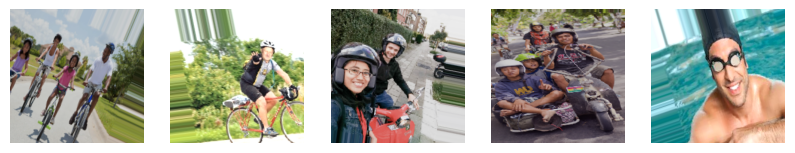

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Get a batch of augmented images
x_batch, y_batch = next(train_generator)

# Plot the first 5 images
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_batch[i])
    plt.axis("off")
plt.show()


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Load Pre-trained ResNet50 (excluding top layers)
base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model initially

# Custom Classification Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.3)(x)
output_layer = Dense(1, activation="sigmoid")(x)  # Binary classification

# Create Model
model = Model(inputs=base_model.input, outputs=output_layer)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Train Model (Initial Phase)
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Unfreeze Some Layers & Fine-tune
base_model.trainable = True
for layer in base_model.layers[:100]:  # Keep first 100 layers frozen
    layer.trainable = False

# Recompile with Lower Learning Rate
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss="binary_crossentropy", metrics=["accuracy"])

# Fine-tune Model
history_finetune = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}")


In [10]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Load Pre-trained ResNet50 (excluding top layers)
base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model initially

# Custom Classification Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.3)(x)
''

output_layer = Dense(1, activation="sigmoid")(x)  # Binary classification

# Create Model
model = Model(inputs=base_model.input, outputs=output_layer)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Train Model (Initial Phase)
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Unfreeze Some Layers & Fine-tune
base_model.trainable = True
for layer in base_model.layers[:100]:  # Keep first 100 layers frozen
    layer.trainable = False

# Recompile with Lower Learning Rate
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss="binary_crossentropy", metrics=["accuracy"])

# Fine-tune Model
history_finetune = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 114s 3s/step - accuracy: 0.5840 - loss: 0.6863 - val_accuracy: 0.7403 - val_loss: 0.4927
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.7254 - loss: 0.5878 - val_accuracy: 0.7901 - val_loss: 0.4438
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 0.7266 - loss: 0.5240 - val_accuracy: 0.7901 - val_loss: 0.4440
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 184s 5s/step - accuracy: 0.7496 - loss: 0.5134 - val_accuracy: 0.8177 - val_loss: 0.4081
Epoch 5/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 240s 7s/step - accuracy: 0.7424 - loss: 0.5204 - val_accuracy: 0.8177 - val_loss: 0.3974
Epoch 6/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 238s 7s/step - accuracy: 0.7625 - loss: 0.4950 - val_accuracy: 0.8287 - val_loss: 0.3888
Epoch 7/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 227s 7s/step - accuracy: 0.7563 - loss: 0.4872 - val_accuracy: 0.8287 - val_loss: 0.4004
Epoch 8/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 307s 9s/step - accuracy: 0.7438 - loss: 0.4832 - val_accuracy: 0.8287 - va

KeyboardInterrupt: 

In [11]:
# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 40s 6s/step - accuracy: 0.8319 - loss: 0.4041
Test Accuracy: 0.8967


Model loaded successfully!
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


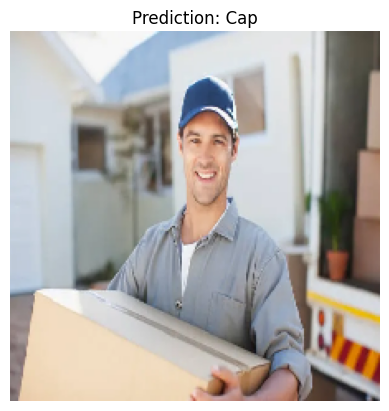

In [20]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Load the saved model
model = tf.keras.models.load_model(r"C:\Users\91994\Desktop\mgit\merged_dataset\helmet_cap_model.h5")
print("Model loaded successfully!")
  # Change filename if needed

# Path to new image
image_path = r"C:\Users\91994\Desktop\mgit\merged_dataset\new_test\image2.webp"  # Change this path

# Load and preprocess image
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
img_array = img_array / 255.0  # Normalize

# Predict
prediction = model.predict(img_array)
predicted_class = "Helmet" if prediction[0][0] > 0.5 else "Cap"

# Display result
plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}")
plt.show()


In [13]:
# Save model to your specified path
model.save(r"C:\Users\91994\Desktop\mgit\merged_dataset\helmet_cap_model.h5")
print("Model saved successfully at C:\\Users\\91994\\Desktop\\mgit\\merged_dataset!")


Model saved successfully at C:\Users\91994\Desktop\mgit\merged_dataset!
